# Lab 1: Build your own spam filter (SMS spam classifier)

**Goal:** train a model that reads a text message and decides **spam** or **ham** (normal message).

This is the same spam example from Day 1's confusion-matrix slide, now with real data. You will practise the full ML lifecycle: load, explore, turn text into numbers, split, train, evaluate and predict.

**Run this in Google Colab:** File > Upload notebook, then run each cell with Shift + Enter.

## Step 0: Get the data from Kaggle

1. Sign in at [kaggle.com](https://www.kaggle.com) and search for **SMS Spam Collection Dataset** (by UCI Machine Learning).
2. Click **Download** and unzip it to get `spam.csv`.
3. In Colab, open the **Files** panel (folder icon, left) and upload `spam.csv`.

No Kaggle account yet? The next cell downloads a public copy of the same 5,572 messages automatically.

In [8]:
import os
import urllib.request
import pandas as pd

if os.path.exists("spam.csv"):
    # Kaggle's file: columns v1 (label) and v2 (text), plus empty extra columns
    df = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]]
else:
    # Public copy of the same UCI dataset, used only if you did not upload spam.csv
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv",
        "sms.tsv")
    df = pd.read_csv("sms.tsv", sep="\t", header=None)

df.columns = ["label", "text"]
print(df.shape)   # (rows, columns)
df.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Step 1: Explore the data (EDA)

Each **row is a data point** (one SMS). The **text** is our input and **label** is what we want to predict.

In [9]:
print(df["label"].value_counts())
print()
print("Share of spam:", round((df["label"] == "spam").mean(), 3))

label
ham     4825
spam     747
Name: count, dtype: int64

Share of spam: 0.134


Only about **13%** of messages are spam. This is an **imbalanced** dataset: remember that, it matters in Step 4.

label
ham      71.0
spam    139.0
Name: length, dtype: float64

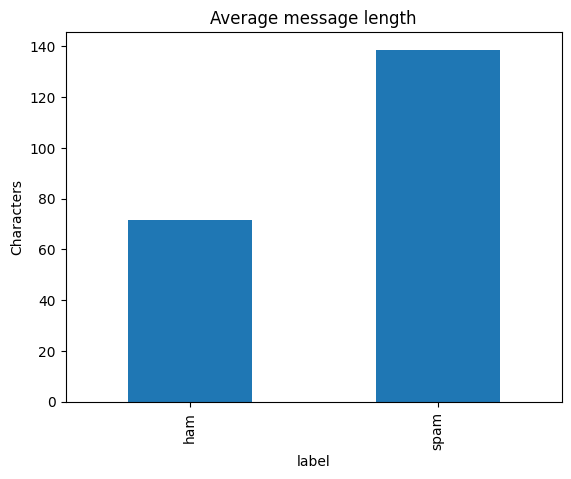

In [10]:
df["length"] = df["text"].str.len()
print(df.groupby("label")["length"].mean().round(0))
df.groupby("label")["length"].mean().plot(kind="bar", title="Average message length", ylabel="Characters");

In [11]:
print("Some spam messages:")
for t in df[df["label"] == "spam"]["text"].head(5):
    print(" -", t)

Some spam messages:
 - Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
 - FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
 - WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
 - Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
 - SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info


## Step 2: Turn text into numbers

Models only understand numbers. **TF-IDF** gives each word a score: high if the word is frequent in this message but rare across all messages.
Here is what it does to three tiny messages:

In [12]:
pip install scikit-learn


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
    --------------------------------------- 0.1/8.3 MB 3.3 MB/s eta 0:00:03
   - -------------------------------------- 0.3/8.3 MB 2.8 MB/s eta 0:00:03
   -- ------------------------------------- 0.6/8.3 MB 3.9 MB/s eta 0:00:02
   ------ --------------------------------- 1.3/8.3 MB 6.9 MB/s eta 0:00:02
   ---------- ----------------------------- 2.2/8.3 MB 9.2 MB/s eta 0:00:01
   ---------------- ----------------------- 3.3/8.3 MB 10.6 MB/s eta 0:00:01
   ---------------- ----------------------- 3.5/8.3 MB 10.6 MB/s eta 0:00:01
   ----------------- ---------------------- 3.6/8.3 MB 8.8 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 9.3 MB/s eta 0:00:01
   ---------------------- ----------------- 4.6/8.3 MB 9.2 MB/s eta 0:00:01
   ----------------------- ---------------- 4.8/8.3 MB 8.7 MB/s eta 0:00:01
   -------------------------- ------------- 5.4/8.3 MB 9.4 MB/s eta 0:00:01
   --------------


[notice] A new release of pip is available: 23.3.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

demo = ["win a free prize now", "are we meeting now", "free free free"]
demo_vec = TfidfVectorizer()
table = pd.DataFrame(demo_vec.fit_transform(demo).toarray(),
                     columns=demo_vec.get_feature_names_out(), index=demo)
table.round(2)

,are,free,meeting,now,prize,we,win
win a free prize now,0.00,0.43,0.00,0.43,0.56,0.00,0.56
are we meeting now,0.53,0.00,0.53,0.40,0.00,0.53,0.00
free free free,0.00,1.00,0.00,0.00,0.00,0.00,0.00


## Step 3: Split into training and test sets

80% to train, 20% held back to test honestly. `stratify=y` keeps the same spam share in both parts.

**Important:** the vectorizer learns its vocabulary from the training set only (`fit_transform`), then just converts the test set (`transform`). Otherwise test data leaks into training.

In [14]:
from sklearn.model_selection import train_test_split

y = (df["label"] == "spam").astype(int)     # spam = 1, ham = 0
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], y, test_size=0.2, random_state=42, stratify=y)

vec = TfidfVectorizer(stop_words="english")   # ignore words like "the", "is"
X_train_vec = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)
print("Train:", X_train_vec.shape, " Test:", X_test_vec.shape, " (messages, words)")

Train: (4457, 7403)  Test: (1115, 7403)  (messages, words)


## Step 4: The accuracy trap (baseline)

The laziest possible "model" says **ham** for every message. Check its accuracy...

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_train_vec, y_train)
base_pred = baseline.predict(X_test_vec)
print("Baseline accuracy:   ", round(accuracy_score(y_test, base_pred), 3))
print("Spam caught (recall):", round(recall_score(y_test, base_pred), 3))

Baseline accuracy:    0.866
Spam caught (recall): 0.0


About **87% accuracy while catching zero spam**. This is why accuracy alone can lie on imbalanced data. Always check recall, precision and F1.

## Step 5: Train two real models

- **Naive Bayes:** the classic spam-filter algorithm, counts which words appear in spam vs ham
- **Logistic regression** with `class_weight="balanced"`: tells the model that missing a spam message matters as much as the rare class deserves

In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, f1_score

nb = MultinomialNB().fit(X_train_vec, y_train)
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000).fit(X_train_vec, y_train)

for name, m in [("Naive Bayes", nb), ("Logistic regression", log_reg)]:
    p = m.predict(X_test_vec)
    print(f"{name:20s} accuracy {accuracy_score(y_test, p):.3f}  "
          f"precision {precision_score(y_test, p):.3f}  "
          f"recall {recall_score(y_test, p):.3f}  F1 {f1_score(y_test, p):.3f}")

Naive Bayes          accuracy 0.970  precision 1.000  recall 0.779  F1 0.875
Logistic regression  accuracy 0.977  precision 0.913  recall 0.913  F1 0.913


Both look great on accuracy, but Naive Bayes misses about 1 in 4 spam messages (recall ~0.77). Balanced logistic regression catches over 90%, at the cost of a few false alarms.

## Step 6: Evaluate properly

The **confusion matrix**, **precision**, **recall** and **F1**, exactly as in the Day 1 worked example.

In [17]:
from sklearn.metrics import confusion_matrix, classification_report

pred = log_reg.predict(X_test_vec)
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred, target_names=["Ham", "Spam"]))

Confusion matrix (rows = actual, columns = predicted):
[[953  13]
 [ 13 136]]

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.91      0.91      0.91       149

    accuracy                           0.98      1115
   macro avg       0.95      0.95      0.95      1115
weighted avg       0.98      0.98      0.98      1115



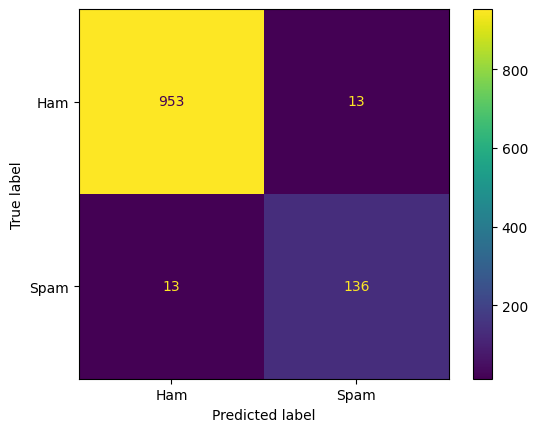

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Ham", "Spam"]);

**Read it out loud:** top-right = good messages wrongly sent to spam (false positives, annoying). Bottom-left = spam that got through (false negatives, risky). Which mistake is worse for your users?

## Step 7: Which words scream "spam"?

Logistic regression gives every word a weight. Big positive = spammy, big negative = normal chat.

Most spammy words: ['txt', 'uk', 'mobile', 'claim', 'www', 'stop', 'service', 'reply', 'free', '150p']
Most normal words: ['ok', 'll', 'gt', 'lt', 'da', 'home', 'come', 'got', 'lor', 'sorry']


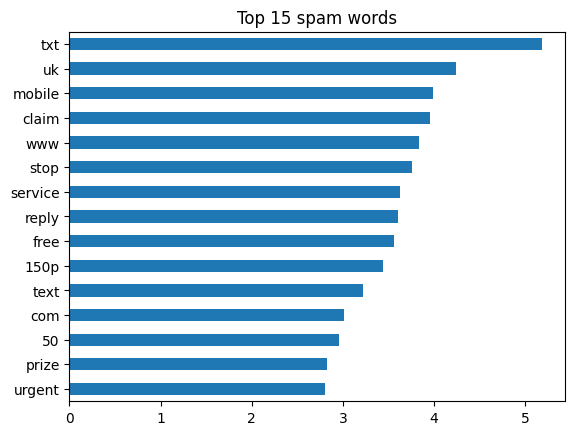

In [19]:
weights = pd.Series(log_reg.coef_[0], index=vec.get_feature_names_out()).sort_values()
print("Most spammy words:", list(weights.index[-10:][::-1]))
print("Most normal words:", list(weights.index[:10]))
weights.tail(15).plot(kind="barh", title="Top 15 spam words");

## Step 8: Try your own messages (inference)

In [20]:
messages = [
    "Congratulations! You have won a cash prize. Call now to claim",
    "URGENT! Your account is blocked, reply with your PIN",
    "Are we still meeting for lunch at 1?",
    "Can you send me the notes from class today?",
]
probs = log_reg.predict_proba(vec.transform(messages))[:, 1]
for msg, p in zip(messages, probs):
    print(f"{p:5.0%} spam  |  {msg}")

  98% spam  |  Congratulations! You have won a cash prize. Call now to claim
  87% spam  |  URGENT! Your account is blocked, reply with your PIN
   9% spam  |  Are we still meeting for lunch at 1?
  17% spam  |  Can you send me the notes from class today?


## Try it yourself

1. Add your own messages to Step 8, including tricky ones. Can you fool the model?
2. Change the decision threshold: flag as spam only when probability > 0.8. What happens to precision and recall?
3. Remove `stop_words="english"` or add `ngram_range=(1, 2)` to the vectorizer. Does F1 improve?
4. Try `class_weight=None` in logistic regression and compare recall.
5. Use `cross_val_score` from `sklearn.model_selection` for a more reliable score.
6. **Stretch:** save the model with `joblib.dump` and load it in a Streamlit app, like Lab 2.